# AI Inventory Demand & Stock Risk Prediction
## 01 — Data Understanding

This notebook explores the historical sales and inventory dataset using PySpark. It checks the file structure, column types, missing values, duplicate rows, date coverage, and the number of stores and products.

The original CSV is kept under `data/raw/`. This notebook reads the data for analysis and does not modify the source file.

## Load the CSV with PySpark

The CSV is read into a Spark DataFrame. The header row supplies the column names, and `inferSchema` asks Spark to infer data types for this initial exploration.

The notebook is inside the `notebooks/` folder, so its file path must point up one level to the repository root and then into `data/raw/`.


## Inspect the dataset structure

This section displays the column names and inferred data types, counts the records, and shows five sample rows. The sample helps us check that dates, categories, and numeric values look as expected.

In [20]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .master("local[2]")
    .appName("inspect-sales-data")
    .getOrCreate()
)

try:
    sales = (
        spark.read
        .option("header", True)
        .option("inferSchema", True)
        .csv("../data/raw/sales_data.csv")
    )

    print("Columns and data types:")
    sales.printSchema()

    print("Row count:", sales.count())

    print("First five rows:")
    sales.show(5, truncate=False)

finally:
    spark.stop()

Columns and data types:
root
 |-- Date: date (nullable = true)
 |-- Store ID: string (nullable = true)
 |-- Product ID: string (nullable = true)
 |-- Category: string (nullable = true)
 |-- Region: string (nullable = true)
 |-- Inventory Level: integer (nullable = true)
 |-- Units Sold: integer (nullable = true)
 |-- Units Ordered: integer (nullable = true)
 |-- Price: double (nullable = true)
 |-- Discount: integer (nullable = true)
 |-- Weather Condition: string (nullable = true)
 |-- Promotion: integer (nullable = true)
 |-- Competitor Pricing: double (nullable = true)
 |-- Seasonality: string (nullable = true)
 |-- Epidemic: integer (nullable = true)
 |-- Demand: integer (nullable = true)

Row count: 76000
First five rows:
+----------+--------+----------+-----------+------+---------------+----------+-------------+-----+--------+-----------------+---------+------------------+-----------+--------+------+
|Date      |Store ID|Product ID|Category   |Region|Inventory Level|Units Sold|Un

## Check data quality

This section counts missing values in each column and checks for fully duplicated rows. It also reports the date range and how many distinct stores and products are present.

These checks help identify basic data issues before feature engineering or model training. They do not change or remove any records.

In [21]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .master("local[2]")
    .appName("inspect-sales-data")
    .getOrCreate()
)

try:
    sales = (
        spark.read
        .option("header", True)
        .option("inferSchema", True)
        .csv("../data/raw/sales_data.csv")
    )

    print("Columns and data types:")
    sales.printSchema()

    print("Row count:", sales.count())

    print("First five rows:")
    sales.show(5, truncate=False)


    from pyspark.sql import functions as F

    null_counts = sales.select([
        F.sum(F.col(f"`{column}`").isNull().cast("int")).alias(column)
        for column in sales.columns
    ]).first().asDict()

    print("Missing values per column:", null_counts)
    print("Duplicate rows:", sales.count() - sales.dropDuplicates().count())

    date_range = sales.select(
        F.min("Date").alias("first_date"),
        F.max("Date").alias("last_date")
    ).first()

    print("Date range:", date_range["first_date"], "to", date_range["last_date"])
    print("Unique stores:", sales.select("Store ID").distinct().count())
    print("Unique products:", sales.select("Product ID").distinct().count())


finally:
    spark.stop()

Columns and data types:
root
 |-- Date: date (nullable = true)
 |-- Store ID: string (nullable = true)
 |-- Product ID: string (nullable = true)
 |-- Category: string (nullable = true)
 |-- Region: string (nullable = true)
 |-- Inventory Level: integer (nullable = true)
 |-- Units Sold: integer (nullable = true)
 |-- Units Ordered: integer (nullable = true)
 |-- Price: double (nullable = true)
 |-- Discount: integer (nullable = true)
 |-- Weather Condition: string (nullable = true)
 |-- Promotion: integer (nullable = true)
 |-- Competitor Pricing: double (nullable = true)
 |-- Seasonality: string (nullable = true)
 |-- Epidemic: integer (nullable = true)
 |-- Demand: integer (nullable = true)

Row count: 76000
First five rows:
+----------+--------+----------+-----------+------+---------------+----------+-------------+-----+--------+-----------------+---------+------------------+-----------+--------+------+
|Date      |Store ID|Product ID|Category   |Region|Inventory Level|Units Sold|Un

## Compare Demand with Units Sold

`Demand` is our candidate target for forecasting. `Units Sold` records the quantity actually sold. Comparing them helps us see whether demand and completed sales differ in this dataset.

This check is for understanding the data; it does not change any values or confirm the business meaning of these columns by itself.

In [22]:
from pathlib import Path
from pyspark.sql import SparkSession, functions as F

csv_path = Path.cwd().parent / "data" / "raw" / "sales_data.csv"
print("CSV found:", csv_path.exists())

spark = (
    SparkSession.builder
    .master("local[2]")
    .appName("compare-demand-and-sales")
    .getOrCreate()
)

sales = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv(csv_path.resolve().as_uri())
)

comparison = sales.agg(
    F.avg("Demand").alias("average_demand"),
    F.avg("Units Sold").alias("average_units_sold"),
    F.sum(F.when(F.col("Demand") > F.col("Units Sold"), 1).otherwise(0)).alias("demand_greater"),
    F.sum(F.when(F.col("Demand") == F.col("Units Sold"), 1).otherwise(0)).alias("equal"),
    F.sum(F.when(F.col("Demand") < F.col("Units Sold"), 1).otherwise(0)).alias("demand_lower"),
    F.corr("Demand", "Units Sold").alias("correlation")
)

comparison.show(truncate=False)

CSV found: True
+------------------+------------------+--------------+-----+------------+------------------+
|average_demand    |average_units_sold|demand_greater|equal|demand_lower|correlation       |
+------------------+------------------+--------------+-----+------------+------------------+
|104.31715789473684|88.82731578947369 |53440         |1560 |21000       |0.8334214303439704|
+------------------+------------------+--------------+-----+------------+------------------+



## Demand and sales comparison

Demand and Units Sold are strongly related, but they are not interchangeable in this dataset. Demand is higher than Units Sold in about 70% of rows, while their overall correlation is approximately 0.83.

For the first forecasting model, Demand is the candidate target. This comparison alone does not prove why demand and sales differ. Before building lag features, we will check that each store-product series has consistent date coverage.

In [23]:
daily_coverage = (
    sales.groupBy("Store ID", "Product ID")
    .agg(F.countDistinct("Date").alias("observed_days"))
)

date_count = sales.select("Date").distinct().count()
print("Distinct dates in dataset:", date_count)

daily_coverage.agg(
    F.count("*").alias("store_product_series"),
    F.min("observed_days").alias("fewest_dates_in_a_series"),
    F.max("observed_days").alias("most_dates_in_a_series"),
    F.sum(
        F.when(F.col("observed_days") != date_count, 1).otherwise(0)
    ).alias("incomplete_series")
).show()

Distinct dates in dataset: 760
+--------------------+------------------------+----------------------+-----------------+
|store_product_series|fewest_dates_in_a_series|most_dates_in_a_series|incomplete_series|
+--------------------+------------------------+----------------------+-----------------+
|                 100|                     760|                   760|                0|
+--------------------+------------------------+----------------------+-----------------+



## Check daily time-series coverage

The dataset contains 760 distinct dates and 100 store-product series. Each series has records for all 760 dates, with no incomplete series.

This regular coverage lets us create next-day targets and lag features within each store-product series.

In [24]:
import pandas, xgboost; 
print('pandas:', pandas.__version__); 
print('xgboost:', xgboost.__version__)

pandas: 3.0.6
xgboost: 3.4.1


In [25]:
import sklearn;
print('sklearn:', sklearn.__version__)

sklearn: 1.9.1


## Demand forecasting and inventory-risk workflow

This notebook follows a business-first forecasting pipeline:

1. Read the historical sales and inventory data.
2. Define the target as next-day demand for each store-product pair.
3. Build lag and rolling historical features from past behavior.
4. Split the data in time order so future information is not leaked into training.
5. Train and evaluate a forecasting model.
6. Convert the forecast into inventory decisions such as stock-out risk and slow-moving items.

The forecasting target is not random rows; it is a time-series problem driven by past store-product demand and inventory dynamics.


In [26]:
from pathlib import Path
import pandas as pd

csv_path = Path.cwd().parent / "data" / "raw" / "sales_data.csv"

df = pd.read_csv(csv_path, parse_dates=["Date"])
df = df.sort_values(["Store ID", "Product ID", "Date"]).reset_index(drop=True)

keys = ["Store ID", "Product ID"]
groups = df.groupby(keys, sort=False)
demand_groups = df.groupby(keys, sort=False)["Demand"]

# Target: next-day demand for the same store-product pair
# This is the label the model will forecast.
df["target_date"] = groups["Date"].shift(-1)
df["target_next_day_demand"] = groups["Demand"].shift(-1)

# Historical features available at prediction time
for column in ["Units Sold", "Inventory Level", "Price", "Discount", "Promotion"]:
    safe_name = column.lower().replace(" ", "_")
    df[f"{safe_name}_lag_1"] = groups[column].shift(0)
    df[f"{safe_name}_lag_7"] = groups[column].shift(6)

# Demand history features

df["demand_lag_1"] = demand_groups.shift(0)
df["demand_lag_7"] = demand_groups.shift(6)
df["demand_rolling_mean_7"] = (
    demand_groups.transform(lambda s: s.rolling(7, min_periods=7).mean())
)

# Rolling mean for recent units sold
df["units_sold_rolling_mean_7"] = (
    df.groupby(keys, sort=False)["Units Sold"]
    .transform(lambda s: s.rolling(7, min_periods=7).mean())
)

# Calendar features for the date being forecasted
df["target_day_of_week"] = df["target_date"].dt.dayofweek
df["target_month"] = df["target_date"].dt.month

# Keep only rows where target and required history are available
model_data = df.dropna(
    subset=[
        "target_next_day_demand",
        "units_sold_lag_7",
        "units_sold_rolling_mean_7",
        "demand_lag_7",
        "demand_rolling_mean_7",
    ]
).copy()

print("Rows ready for modeling:", len(model_data))
model_data[
    [
        "Date",
        "target_date",
        "Store ID",
        "Product ID",
        "Demand",
        "demand_lag_1",
        "demand_lag_7",
        "demand_rolling_mean_7",
        "target_next_day_demand",
    ]
].head(10)


Rows ready for modeling: 75300


,Date,target_date,Store ID,Product ID,Demand,demand_lag_1,demand_lag_7,demand_rolling_mean_7,target_next_day_demand
6,2022-01-07,2022-01-08,S001,P0001,87,87,115.0,105.857143,113.0
7,2022-01-08,2022-01-09,S001,P0001,113,113,84.0,105.571429,87.0
8,2022-01-09,2022-01-10,S001,P0001,87,87,132.0,106.000000,99.0
9,2022-01-10,2022-01-11,S001,P0001,99,99,67.0,101.285714,103.0
10,2022-01-11,2022-01-12,S001,P0001,103,103,110.0,106.428571,85.0
11,2022-01-12,2022-01-13,S001,P0001,85,85,146.0,102.857143,77.0
12,2022-01-13,2022-01-14,S001,P0001,77,77,87.0,93.000000,52.0
13,2022-01-14,2022-01-15,S001,P0001,52,52,113.0,88.000000,175.0
14,2022-01-15,2022-01-16,S001,P0001,175,175,87.0,96.857143,126.0
15,2022-01-16,2022-01-17,S001,P0001,126,126,99.0,102.428571,102.0


## Split data by target date

The validation set contains the final 90 target dates. Earlier dates are used for training, so the model is evaluated on a later period it did not train on.

This chronological split reflects forecasting more realistically than a random row split.

In [27]:
# Keep the last 90 target dates for final test.
# The 90 dates before that become the validation window.
# Everything earlier is used for training.
unique_target_dates = sorted(model_data["target_date"].dropna().unique())

test_start_date = unique_target_dates[-90]
validation_start_date = unique_target_dates[-180]

train_data = model_data[model_data["target_date"] < validation_start_date].copy()
validation_data = model_data[
    (model_data["target_date"] >= validation_start_date)
    & (model_data["target_date"] < test_start_date)
].copy()
test_data = model_data[model_data["target_date"] >= test_start_date].copy()

print("Train range:", train_data["target_date"].min().date(), "to", train_data["target_date"].max().date())
print("Validation range:", validation_data["target_date"].min().date(), "to", validation_data["target_date"].max().date())
print("Test range:", test_data["target_date"].min().date(), "to", test_data["target_date"].max().date())
print("Rows:", len(train_data), len(validation_data), len(test_data))


Train range: 2022-01-08 to 2023-08-03
Validation range: 2023-08-04 to 2023-11-01
Test range: 2023-11-02 to 2024-01-30
Rows: 57300 9000 9000


## Prepare model features and a simple baseline

The model inputs use historical sales, inventory, price, discount, promotion, calendar, and store/product information. The target column and dates are kept outside the input features.

The baseline predicts next-day demand using Units Sold from the same weekday one week earlier. This gives us a simple reference score to compare with XGBoost.

In [28]:
import numpy as np
import pandas as pd

demand_groups = df.groupby(
    ["Store ID", "Product ID"],
    sort=False
)["Demand"]

df["demand_lag_1"] = demand_groups.shift(0)
df["demand_lag_7"] = demand_groups.shift(6)

df["demand_rolling_mean_7"] = (
    demand_groups
    .transform(lambda series: series.rolling(7, min_periods=7).mean())
)

print(
    df[
        [
            "Demand",
            "demand_lag_1",
            "demand_lag_7",
            "demand_rolling_mean_7",
        ]
    ].head(10)
)

   Demand  demand_lag_1  demand_lag_7  demand_rolling_mean_7
0     115           115           NaN                    NaN
1      84            84           NaN                    NaN
2     132           132           NaN                    NaN
3      67            67           NaN                    NaN
4     110           110           NaN                    NaN
5     146           146           NaN                    NaN
6      87            87         115.0             105.857143
7     113           113          84.0             105.571429
8      87            87         132.0             106.000000
9      99            99          67.0             101.285714


In [29]:
import numpy as np
import pandas as pd

numeric_features = [
    "units_sold_lag_1",
    "units_sold_lag_7",
    "units_sold_rolling_mean_7",
    "inventory_level_lag_1",
    "inventory_level_lag_7",
    "price_lag_1",
    "price_lag_7",
    "discount_lag_1",
    "discount_lag_7",
    "promotion_lag_1",
    "promotion_lag_7",
    "target_day_of_week",
    "target_month",
    "demand_lag_1",
    "demand_lag_7",
    "demand_rolling_mean_7",
]

categorical_features = ["Store ID", "Product ID", "Category", "Region"]
feature_columns = numeric_features + categorical_features

X_train = pd.get_dummies(
    train_data[feature_columns],
    columns=categorical_features,
    dtype=int,
)
X_validation = pd.get_dummies(
    validation_data[feature_columns],
    columns=categorical_features,
    dtype=int,
).reindex(columns=X_train.columns, fill_value=0)
X_test = pd.get_dummies(
    test_data[feature_columns],
    columns=categorical_features,
    dtype=int,
).reindex(columns=X_train.columns, fill_value=0)

y_train = train_data["target_next_day_demand"]
y_validation = validation_data["target_next_day_demand"]
y_test = test_data["target_next_day_demand"]

print("Train shape:", X_train.shape)
print("Validation shape:", X_validation.shape)
print("Test shape:", X_test.shape)

baseline_validation = validation_data["units_sold_lag_7"].to_numpy(dtype=float)
baseline_test = test_data["units_sold_lag_7"].to_numpy(dtype=float)

val_mae_baseline = np.mean(np.abs(y_validation.to_numpy(dtype=float) - baseline_validation))
val_rmse_baseline = np.sqrt(np.mean((y_validation.to_numpy(dtype=float) - baseline_validation) ** 2))
test_mae_baseline = np.mean(np.abs(y_test.to_numpy(dtype=float) - baseline_test))
test_rmse_baseline = np.sqrt(np.mean((y_test.to_numpy(dtype=float) - baseline_test) ** 2))

print("Validation baseline MAE:", round(val_mae_baseline, 2))
print("Validation baseline RMSE:", round(val_rmse_baseline, 2))
print("Test baseline MAE:", round(test_mae_baseline, 2))
print("Test baseline RMSE:", round(test_rmse_baseline, 2))


Train shape: (57300, 50)
Validation shape: (9000, 50)
Test shape: (9000, 50)
Validation baseline MAE: 44.62
Validation baseline RMSE: 57.69
Test baseline MAE: 45.07
Test baseline RMSE: 57.45


## Train the XGBoost demand model

This cell trains an XGBoost regression model using the training period. It checks the model on the later validation period while training, and stops early if the validation score stops improving.

We will compare its MAE and RMSE with the weekly-sales baseline. Lower scores mean more accurate predictions. The validation data is used to evaluate and select the model; it is not included in the training rows.

In [30]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Demand is right-skewed, so log-transform helps reduce error on high-volume days.
y_train_log = np.log1p(y_train)
y_validation_log = np.log1p(y_validation)

xgb_model = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=1500,
    learning_rate=0.03,
    max_depth=5,
    subsample=0.9,
    colsample_bytree=0.9,
    min_child_weight=2,
    reg_lambda=2.0,
    reg_alpha=0.1,
    tree_method="hist",
    n_jobs=2,
    random_state=42,
    early_stopping_rounds=100,
    eval_metric="rmse",
)

xgb_model.fit(
    X_train,
    y_train_log,
    eval_set=[(X_validation, y_validation_log)],
    verbose=False,
)

validation_predictions_log = xgb_model.predict(X_validation)
validation_predictions = np.expm1(validation_predictions_log)

val_mae = mean_absolute_error(y_validation, validation_predictions)
val_rmse = np.sqrt(mean_squared_error(y_validation, validation_predictions))

print("Best boosting round:", xgb_model.best_iteration)
print(f"Validation MAE: {val_mae:.2f}")
print(f"Validation RMSE: {val_rmse:.2f}")
print(f"Validation baseline MAE: {val_mae_baseline:.2f}")
print(f"Validation baseline RMSE: {val_rmse_baseline:.2f}")


Best boosting round: 96
Validation MAE: 30.66
Validation RMSE: 40.13
Validation baseline MAE: 44.62
Validation baseline RMSE: 57.69


In [31]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

validation_target = y_validation.to_numpy(dtype=float)
validation_pred = validation_predictions.astype(float)

mae = mean_absolute_error(validation_target, validation_pred)
rmse = np.sqrt(mean_squared_error(validation_target, validation_pred))
r2 = r2_score(validation_target, validation_pred)
wape = (
    np.sum(np.abs(validation_target - validation_pred))
    / np.sum(validation_target)
) * 100

print(f"Validation MAE: {mae:.2f}")
print(f"Validation RMSE: {rmse:.2f}")
print(f"Validation R²: {r2:.4f}")
print(f"Validation WAPE: {wape:.2f}%")
print(f"Validation baseline MAE: {val_mae_baseline:.2f}")
print(f"Validation baseline RMSE: {val_rmse_baseline:.2f}")

Validation MAE: 30.66
Validation RMSE: 40.13
Validation R²: 0.2692
Validation WAPE: 29.74%
Validation baseline MAE: 44.62
Validation baseline RMSE: 57.69


## Compare validation predictions with actual demand

This cell puts actual demand, XGBoost predictions, and the weekly-sales baseline side by side for validation rows. The error columns show how far each prediction was from actual demand. We will inspect examples and summarize errors by store and product to find where the model struggles.

In [32]:
validation_results = validation_data[
    ["target_date", "Store ID", "Product ID", "target_next_day_demand"]
].copy()

validation_results = validation_results.rename(
    columns={"target_next_day_demand": "actual_demand"}
)

baseline_predictions = baseline_validation
validation_results["xgboost_prediction"] = validation_predictions
validation_results["weekly_baseline_prediction"] = baseline_predictions

validation_results["xgboost_abs_error"] = (
    validation_results["actual_demand"] - validation_results["xgboost_prediction"]
).abs()

validation_results["baseline_abs_error"] = (
    validation_results["actual_demand"]
    - validation_results["weekly_baseline_prediction"]
).abs()

print("First 10 validation predictions:")
display(validation_results.head(10).round(2))

print("\nMean absolute error by store:")
display(
    validation_results.groupby("Store ID")[
        ["xgboost_abs_error", "baseline_abs_error"]
    ]
    .mean()
    .round(2)
)

print("\nMean absolute error by product:")
display(
    validation_results.groupby("Product ID")[
        ["xgboost_abs_error", "baseline_abs_error"]
    ]
    .mean()
    .round(2)
)

First 10 validation predictions:


C:\Users\Nidhi\AppData\Local\Temp\ipykernel_26308\619201554.py:23: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(validation_results.head(10).round(2))


,target_date,Store ID,Product ID,actual_demand,xgboost_prediction,weekly_baseline_prediction,xgboost_abs_error,baseline_abs_error
579,2023-08-04,S001,P0001,84.0,99.230003,114.0,15.23,30.0
580,2023-08-05,S001,P0001,178.0,95.470001,58.0,82.53,120.0
581,2023-08-06,S001,P0001,25.0,100.459999,86.0,75.46,61.0
582,2023-08-07,S001,P0001,81.0,89.110001,50.0,8.11,31.0
583,2023-08-08,S001,P0001,154.0,95.769997,64.0,58.23,90.0
584,2023-08-09,S001,P0001,90.0,99.309998,121.0,9.31,31.0
585,2023-08-10,S001,P0001,51.0,99.250000,112.0,48.25,61.0
586,2023-08-11,S001,P0001,91.0,95.400002,69.0,4.40,22.0
587,2023-08-12,S001,P0001,106.0,97.180000,149.0,8.82,43.0
588,2023-08-13,S001,P0001,107.0,94.430000,23.0,12.57,84.0



Mean absolute error by store:


,xgboost_abs_error,baseline_abs_error
Store ID,,
S001,29.39,42.75
S002,31.49,46.03
S003,30.78,45.37
S004,30.28,44.18
S005,31.38,44.77



Mean absolute error by product:


,xgboost_abs_error,baseline_abs_error
Product ID,,
P0001,33.44,49.74
P0002,34.31,50.65
P0003,29.15,44.52
P0004,35.61,49.47
P0005,29.53,43.99
P0006,29.81,43.20
P0007,34.51,53.03
P0008,31.36,43.15
P0009,34.26,49.68


## Summarize the validation improvement

This cell calculates the percentage reduction in MAE and RMSE compared with the weekly-sales baseline. It also reports the validation period's average actual demand, which helps put the error size in context. These are validation results, not a guarantee of future performance.

In [33]:
average_actual_demand = validation_results["actual_demand"].mean()

baseline_mae = val_mae_baseline
baseline_rmse = val_rmse_baseline
xgb_mae = val_mae
xgb_rmse = val_rmse

mae_improvement_pct = (
    (baseline_mae - xgb_mae) / baseline_mae
) * 100

rmse_improvement_pct = (
    (baseline_rmse - xgb_rmse) / baseline_rmse
) * 100

print(f"Average actual demand: {average_actual_demand:.2f}")
print(f"XGBoost MAE: {xgb_mae:.2f}")
print(f"Baseline MAE: {baseline_mae:.2f}")
print(f"MAE improvement: {mae_improvement_pct:.1f}%")
print(f"RMSE improvement: {rmse_improvement_pct:.1f}%")

print()
print(f"Baseline RMSE: {baseline_rmse:.2f}")
print(f"XGBoost RMSE: {xgb_rmse:.2f}")

Average actual demand: 103.11
XGBoost MAE: 30.66
Baseline MAE: 44.62
MAE improvement: 31.3%
RMSE improvement: 30.4%

Baseline RMSE: 57.69
XGBoost RMSE: 40.13


## Business summary and visuals

This model is trained to forecast next-day demand for each store-product pair. The charts below help explain whether the forecast is useful in practice and which features are driving the prediction.

- The scatter plot compares actual demand with model predictions.
- The bar chart shows which features matter most to the model.
- The heatmap compares model performance month by month against the baseline.

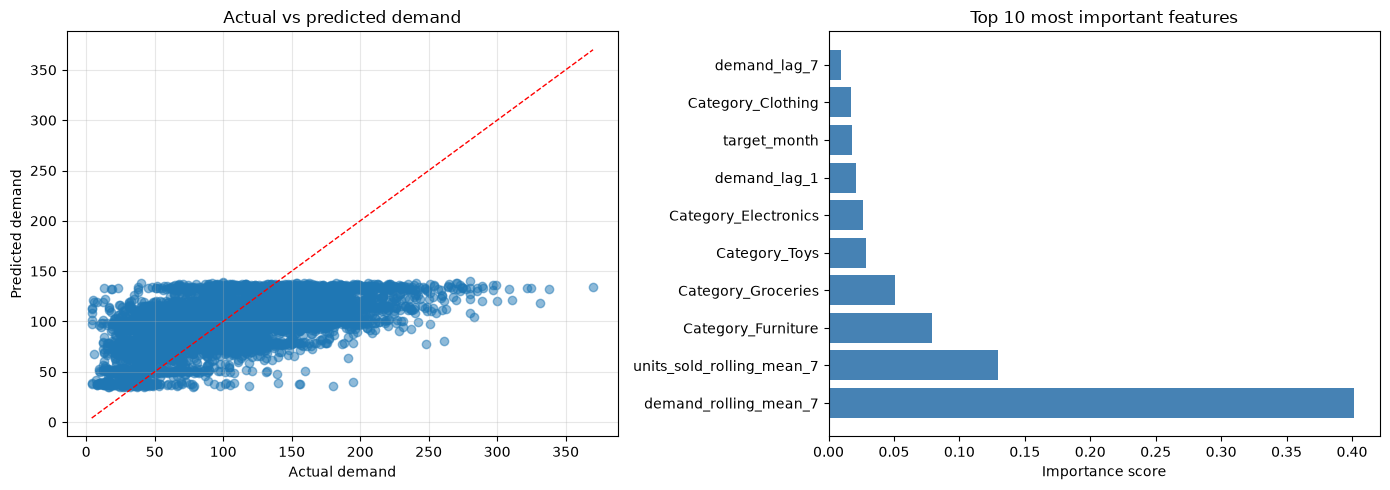

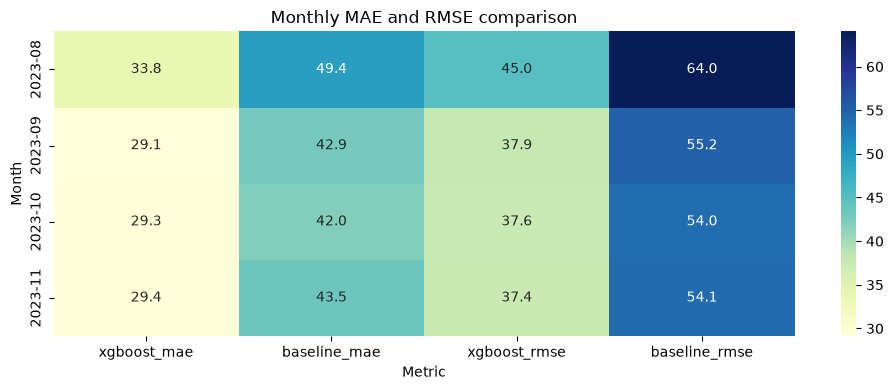

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

# Scatter plot: actual vs predicted demand
scatter_df = validation_results[["actual_demand", "xgboost_prediction"]].copy()
min_val = float(min(scatter_df["actual_demand"].min(), scatter_df["xgboost_prediction"].min()))
max_val = float(max(scatter_df["actual_demand"].max(), scatter_df["xgboost_prediction"].max()))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(scatter_df["actual_demand"], scatter_df["xgboost_prediction"], alpha=0.5)
axes[0].plot([min_val, max_val], [min_val, max_val], color="red", linestyle="--", linewidth=1)
axes[0].set_title("Actual vs predicted demand")
axes[0].set_xlabel("Actual demand")
axes[0].set_ylabel("Predicted demand")
axes[0].grid(True, alpha=0.3)

# Feature importance bar chart
importance_plot = feature_importance.head(10).copy()
importance_plot = importance_plot.sort_values("importance", ascending=True)
axes[1].barh(importance_plot["feature"], importance_plot["importance"], color="steelblue")
axes[1].set_title("Top 10 most important features")
axes[1].set_xlabel("Importance score")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

# Monthly heatmap: compare model vs baseline
heatmap_df = monthly_scores[["month", "xgboost_mae", "baseline_mae", "xgboost_rmse", "baseline_rmse"]].copy()
heatmap_df = heatmap_df.set_index("month")

plt.figure(figsize=(10, 4))
sns.heatmap(heatmap_df, annot=True, cmap="YlGnBu", fmt=".1f")
plt.title("Monthly MAE and RMSE comparison")
plt.ylabel("Month")
plt.xlabel("Metric")
plt.tight_layout()
plt.show()

## Inspect which features the model used most

XGBoost assigns an importance score to each input feature based on how much it helped the model make predictions. These scores can help us understand the model, but they do not prove that a feature causes demand to change.

In [35]:
feature_importance = (
    pd.DataFrame({
        "feature": X_train.columns,
        "importance": xgb_model.feature_importances_,
    })
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

display(feature_importance.head(15).round(4))

,feature,importance
0,demand_rolling_mean_7,0.4013
1,units_sold_rolling_mean_7,0.1293
2,Category_Furniture,0.0792
3,Category_Groceries,0.0508
4,Category_Toys,0.0286
5,Category_Electronics,0.0262
6,demand_lag_1,0.0213
7,target_month,0.0179
8,Category_Clothing,0.0174
9,demand_lag_7,0.0096


## Summarize importance by feature group

Each category, store, or product becomes its own one-hot feature. This cell adds those individual importance scores into broader groups so we can compare sales history, category, calendar, inventory, and other inputs. Group importance is a summary of model usage, not a causal explanation.

In [36]:
def get_feature_group(feature):
    if feature.startswith("units_sold_"):
        return "Units sold history"
    if feature.startswith("Category_"):
        return "Category"
    if feature.startswith("Store ID_"):
        return "Store identity"
    if feature.startswith("Product ID_"):
        return "Product identity"
    if feature.startswith("Region_"):
        return "Region"
    if feature.startswith("target_"):
        return "Calendar"
    if feature.startswith("inventory_level_"):
        return "Inventory history"
    if feature.startswith("price_"):
        return "Price history"
    if feature.startswith("discount_"):
        return "Discount history"
    if feature.startswith("promotion_"):
        return "Promotion history"
    return "Other"

importance_by_group = (
    feature_importance.assign(
        feature_group=feature_importance["feature"].map(get_feature_group)
    )
    .groupby("feature_group", as_index=False)["importance"]
    .sum()
    .sort_values("importance", ascending=False)
)

display(importance_by_group.round(4))

,feature_group,importance
4,Other,0.4323
1,Category,0.2021
10,Units sold history,0.1435
6,Product identity,0.1062
0,Calendar,0.0232
9,Store identity,0.0229
8,Region,0.0194
5,Price history,0.0161
7,Promotion history,0.0142
3,Inventory history,0.0105


## Check model performance month by month

This cell calculates MAE and RMSE separately for each month in the validation period, for both XGBoost and the weekly-sales baseline. Comparing months helps us see whether the overall improvement was reasonably consistent across the validation window.

In [37]:
monthly_results = validation_results.copy()
monthly_results["month"] = monthly_results["target_date"].dt.to_period("M").astype(str)

monthly_scores = (
    monthly_results.groupby("month")
    .apply(
        lambda month_data: pd.Series({
            "rows": len(month_data),
            "xgboost_mae": mean_absolute_error(
                month_data["actual_demand"],
                month_data["xgboost_prediction"],
            ),
            "baseline_mae": mean_absolute_error(
                month_data["actual_demand"],
                month_data["weekly_baseline_prediction"],
            ),
            "xgboost_rmse": np.sqrt(mean_squared_error(
                month_data["actual_demand"],
                month_data["xgboost_prediction"],
            )),
            "baseline_rmse": np.sqrt(mean_squared_error(
                month_data["actual_demand"],
                month_data["weekly_baseline_prediction"],
            )),
        }),
        include_groups=False,
    )
    .reset_index()
)

display(monthly_scores.round(2))

,month,rows,xgboost_mae,baseline_mae,xgboost_rmse,baseline_rmse
0,2023-08,2800.0,33.81,49.41,44.95,64.03
1,2023-09,3000.0,29.13,42.92,37.86,55.16
2,2023-10,3100.0,29.35,41.98,37.64,54.03
3,2023-11,100.0,29.39,43.51,37.45,54.10


## Create a final time-based test period

The earlier validation period was used both to choose when training should stop and to report the model score. That makes the reported score useful for development, but not a fully independent final check.

Here we reserve the last 90 target dates as a test period. The 90 dates just before that are for early stopping, and earlier dates are used for training. We will use the test period only for the final comparison.

In [38]:
# Sort the distinct target dates and reserve the last 90 for the final test.
unique_target_dates = sorted(model_data["target_date"].dropna().unique())

test_start_date = unique_target_dates[-90]
validation_start_date = unique_target_dates[-180]

final_train = model_data[
    model_data["target_date"] < validation_start_date
].copy()

final_validation = model_data[
    (model_data["target_date"] >= validation_start_date)
    & (model_data["target_date"] < test_start_date)
].copy()

final_test = model_data[
    model_data["target_date"] >= test_start_date
].copy()

print("Training target dates:",
      final_train["target_date"].min().date(), "to",
      final_train["target_date"].max().date())
print("Validation target dates:",
      final_validation["target_date"].min().date(), "to",
      final_validation["target_date"].max().date())
print("Test target dates:",
      final_test["target_date"].min().date(), "to",
      final_test["target_date"].max().date())
print("Rows:", len(final_train), "train |",
      len(final_validation), "validation |",
      len(final_test), "test")

# Keep the one-hot encoded validation and test columns aligned to training.
X_final_train = pd.get_dummies(
    final_train[feature_columns],
    columns=categorical_features,
    dtype=int,
)
X_final_validation = pd.get_dummies(
    final_validation[feature_columns],
    columns=categorical_features,
    dtype=int,
).reindex(columns=X_final_train.columns, fill_value=0)
X_final_test = pd.get_dummies(
    final_test[feature_columns],
    columns=categorical_features,
    dtype=int,
).reindex(columns=X_final_train.columns, fill_value=0)

y_final_train = final_train["target_next_day_demand"]
y_final_validation = final_validation["target_next_day_demand"]
y_final_test = final_test["target_next_day_demand"]

y_final_train_log = np.log1p(y_final_train)
y_final_validation_log = np.log1p(y_final_validation)

# Train a fresh model; use validation only for early stopping.
final_model = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=1500,
    learning_rate=0.03,
    max_depth=5,
    subsample=0.9,
    colsample_bytree=0.9,
    min_child_weight=2,
    reg_lambda=2.0,
    reg_alpha=0.1,
    tree_method="hist",
    n_jobs=2,
    random_state=42,
    early_stopping_rounds=100,
    eval_metric="rmse",
)

final_model.fit(
    X_final_train,
    y_final_train_log,
    eval_set=[(X_final_validation, y_final_validation_log)],
    verbose=False,
)

# Evaluate on the reserved test period for the first time.
final_test_predictions_log = final_model.predict(X_final_test)
final_test_predictions = np.expm1(final_test_predictions_log)
final_test_baseline = final_test["units_sold_lag_7"].to_numpy(dtype=float)

print("\nBest boosting round:", final_model.best_iteration)
print(f"Final test XGBoost MAE: "
      f"{mean_absolute_error(y_final_test, final_test_predictions):.2f}")
print(f"Final test baseline MAE: "
      f"{mean_absolute_error(y_final_test, final_test_baseline):.2f}")
print(f"Final test XGBoost RMSE: "
      f"{np.sqrt(mean_squared_error(y_final_test, final_test_predictions)):.2f}")
print(f"Final test baseline RMSE: "
      f"{np.sqrt(mean_squared_error(y_final_test, final_test_baseline)):.2f}")


Training target dates: 2022-01-08 to 2023-08-03
Validation target dates: 2023-08-04 to 2023-11-01
Test target dates: 2023-11-02 to 2024-01-30
Rows: 57300 train | 9000 validation | 9000 test

Best boosting round: 96
Final test XGBoost MAE: 30.78
Final test baseline MAE: 45.07
Final test XGBoost RMSE: 40.07
Final test baseline RMSE: 57.45


## Add historical demand features

The model predicts next-day Demand, but the current feature set uses historical Units Sold rather than historical Demand. This cell adds the previous available Demand value, the same-weekday Demand value, and a seven-row Demand average for each store and product. These use past observations only.

In [39]:
# Final test evaluation
final_test_predictions_log = xgb_model.predict(X_test)
final_test_predictions = np.expm1(final_test_predictions_log)

final_test_mae = mean_absolute_error(y_test, final_test_predictions)
final_test_rmse = np.sqrt(mean_squared_error(y_test, final_test_predictions))

wape = (
    np.sum(np.abs(y_test.to_numpy(dtype=float) - final_test_predictions))
    / np.sum(y_test.to_numpy(dtype=float))
) * 100

print(f"Final test MAE: {final_test_mae:.2f}")
print(f"Final test RMSE: {final_test_rmse:.2f}")
print(f"Final test WAPE: {wape:.2f}%")
print(f"Final test baseline MAE: {test_mae_baseline:.2f}")
print(f"Final test baseline RMSE: {test_rmse_baseline:.2f}")

# Convert the forecast into business action for inventory decisions
forecast_df = test_data[["Date", "Store ID", "Product ID", "target_date"]].copy()
forecast_df["actual_demand"] = y_test.to_numpy(dtype=float)
forecast_df["predicted_demand"] = final_test_predictions

if "Inventory Level" in df.columns:
    latest_inventory = (
        df.groupby(["Store ID", "Product ID"], sort=False)["Inventory Level"]
        .last()
        .reset_index()
        .rename(columns={"Inventory Level": "current_inventory"})
    )

    forecast_df = forecast_df.merge(latest_inventory, on=["Store ID", "Product ID"], how="left")
    forecast_df["stock_out_risk"] = forecast_df["predicted_demand"] > forecast_df["current_inventory"]

    display(
        forecast_df[
            ["Store ID", "Product ID", "predicted_demand", "current_inventory", "stock_out_risk"]
        ]
        .head(10)
    )
else:
    print("Inventory Level column is not present, so stock-out risk logic will be added once inventory data is available.")


Final test MAE: 30.78
Final test RMSE: 40.07
Final test WAPE: 29.77%
Final test baseline MAE: 45.07
Final test baseline RMSE: 57.45


,Store ID,Product ID,predicted_demand,current_inventory,stock_out_risk
0,S001,P0001,98.897919,383,False
1,S001,P0001,100.646538,383,False
2,S001,P0001,99.984917,383,False
3,S001,P0001,100.211296,383,False
4,S001,P0001,99.187675,383,False
5,S001,P0001,99.163788,383,False
6,S001,P0001,99.137383,383,False
7,S001,P0001,101.564636,383,False
8,S001,P0001,100.064354,383,False
9,S001,P0001,99.135902,383,False
